# RTM–WB Local Networks Connected by FLN

This notebook builds a local circuit for each of the 40 cortical areas. Each area contains one RTM excitatory cell and 40 WB inhibitory cells. Within an area, the 40 WB cells are connected using the all-to-all option from Connectivity_Matrix_ftn.m, with no self-connections. The local RTM cell excites its 40 WB cells; WB cells inhibit the local RTM and one another.

Across areas, the RTM cells are connected by the project's FLN matrix. V4 receives an external pulse. We compare runs with inter-area FLN links disabled and enabled.

This is a first network prototype: 40 RTM cells and 1,600 WB cells total. Parameter values are provisional.

## Step 1: Load the project connectivity and area labels

The same connectivity file supplies FLN and area_list. Keeping this ordering ensures that each FLN projection connects the intended RTM cells.

In [1]:
from pathlib import Path
import sys

project_root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "data").is_dir() and (p / "template_kwargs.py").is_file()),
    None,
)
if project_root is None:
    raise RuntimeError("Start Jupyter from the project root or one of its subdirectories.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import matplotlib.pyplot as plt
from brian2 import (
    NeuronGroup, Synapses, StateMonitor, SpikeMonitor, Network, TimedArray,
    Clock, ms, mV, uA, cm, uF, msiemens, siemens, Hz,
)
from template_kwargs import template_kwargs

connectivity_path = project_root / "data" / template_kwargs["connectivity_file"]
with open(connectivity_path, "rb") as f:
    anatomy = np.load(f, allow_pickle=True, encoding="bytes")

area_labels = [
    x.decode("utf-8") if isinstance(x, bytes) else str(x)
    for x in anatomy[b"area_list"]
]
raw_fln = np.asarray(anatomy[b"fln"], dtype=float)
n_areas = len(area_labels)

assert raw_fln.shape == (n_areas, n_areas)
assert len(set(area_labels)) == n_areas
assert "V4" in area_labels

print("Areas:", n_areas)
print("FLN shape:", raw_fln.shape)
print("V4 index:", area_labels.index("V4"))
print("First 10 area labels:", area_labels[:10])

Areas: 40
FLN shape: (40, 40)
V4 index: 2
First 10 area labels: ['V1', 'V2', 'V4', '1', '3', 'MT', 'V6', 'DP', 'TEO', '8m']


## Step 2: Build the local WB connectivity matrix

Connectivity_Matrix_ftn.m lists ring, all-to-all, and random sparse options, but those code blocks are commented out in the supplied file, so the function currently does not return a matrix. For this first notebook, we use its all-to-all option: every WB cell connects to every other WB cell, and the diagonal is zero so cells do not connect to themselves.

Here W_local[target, source] = 1 means source WB cell inhibits target WB cell. The chosen matrix is symmetric, so reversing the convention would produce the same edges.

WB cells in each area: 40
Local matrix shape: (40, 40)
Incoming WB connections per cell: 39
Total directed WB-to-WB links per area: 1560


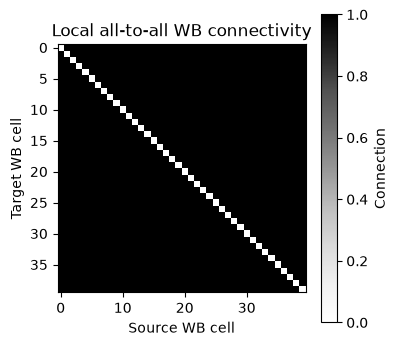

In [2]:
n_wb_per_area = 40
W_local = np.ones((n_wb_per_area, n_wb_per_area), dtype=np.int8)
np.fill_diagonal(W_local, 0)

local_targets, local_sources = np.where(W_local > 0)
print("WB cells in each area:", n_wb_per_area)
print("Local matrix shape:", W_local.shape)
print("Incoming WB connections per cell:", int(W_local.sum(axis=1)[0]))
print("Total directed WB-to-WB links per area:", len(local_sources))

plt.figure(figsize=(4, 4))
plt.imshow(W_local, cmap="Greys", interpolation="nearest")
plt.xlabel("Source WB cell")
plt.ylabel("Target WB cell")
plt.title("Local all-to-all WB connectivity")
plt.colorbar(label="Connection")
plt.show()

## Step 3: Prepare the inter-area FLN weights

The project convention is FLN[target, source]: matrix entry i,j means source area j projects to target area i. We use the same power transform and incoming-row normalization as the original large-scale Model.

In [3]:
fln_a = float(template_kwargs["fln_a"])
fln_b = float(template_kwargs["fln_b"])
scaled_fln = fln_a * np.clip(raw_fln, 0.0, None) ** fln_b
incoming_totals = np.nansum(scaled_fln, axis=1, keepdims=True)
fln_weights = np.divide(
    scaled_fln,
    incoming_totals,
    out=np.zeros_like(scaled_fln),
    where=incoming_totals > 0,
)
fln_weights = np.nan_to_num(fln_weights)

print("FLN direction: source area j -> target area i")
print("Directed inter-area links:", int(np.count_nonzero(fln_weights)))
print("Incoming weight sum range:",
      float(fln_weights.sum(axis=1).min()),
      "to", float(fln_weights.sum(axis=1).max()))
print("Self-links in FLN:", int(np.count_nonzero(np.diag(fln_weights))))

FLN direction: source area j -> target area i
Directed inter-area links: 999
Incoming weight sum range: 0.9999999999999998 to 1.0000000000000002
Self-links in FLN: 0


## Step 4: Set the simulation parameters

There is one RTM cell per area and 40 WB cells per area. The WB-to-RTM and WB-to-WB conductance values below are total local scales; each WB event is divided by the number of WB cells so the total input does not automatically grow forty-fold. The FLN row normalization similarly keeps incoming projection weights comparable across areas.

In [37]:
run_duration = 200 * ms
dt = 0.01 * ms
base_current = 0.0                 # microampere/cm^2
pulse_current = 60               # microampere/cm^2 (provisional)
pulse_on = 50 * ms
pulse_off = 800 * ms
stimulated_area = "V4"

# Provisional synaptic conductance scales
rtm_to_wb_conductance = 0.1 * msiemens / cm**2
wb_to_rtm_total_conductance = 0.5 * msiemens / cm**2
wb_to_wb_total_conductance = 0.1 * msiemens / cm**2
interarea_total_conductance = 0.08 * msiemens / cm**2
tau_exc = 2 * ms
tau_inh = 10 * ms
tau_long = 2 * ms

print("Simulation duration:", run_duration / ms, "ms")
print("Integration step:", dt / ms, "ms")
print("Cells:", n_areas, "RTM and", n_areas * n_wb_per_area, "WB")
print("Stimulus:", stimulated_area, "from", pulse_on / ms, "to", pulse_off / ms, "ms")
print("FLN conductance:", interarea_total_conductance / (msiemens / cm**2), "mS/cm^2")
print("FLN conductance decay:", tau_long / ms, "ms")

Simulation duration: 200.0 ms
Integration step: 0.01 ms
Cells: 40 RTM and 1600 WB
Stimulus: V4 from 50.0 to 800.0 ms
FLN conductance: 0.08 mS/cm^2
FLN conductance decay: 2.0 ms


## Step 5: Define the RTM and WB cell equations

RTM cells receive the external pulse, local WB inhibition, and long-range excitatory input from other RTM cells. WB cells receive local RTM excitation and inhibition from the other WB cells in their area.

In [38]:
rtm_equations = "\n".join([
    "dv/dt = (I_app + I_inh + I_long - gNa*m_inf**3*h*(v-vNa) - gK*n**4*(v-vK) - gL*(v-vL))/C_m : volt",
    "dh/dt = alpha_h*(1-h)-beta_h*h : 1",
    "dn/dt = alpha_n*(1-n)-beta_n*n : 1",
    "alpha_m = (1.28/ms)/exprel(-(v/mV+54)/4) : Hz",
    "beta_m = (1.4/ms)/exprel((v/mV+27)/5) : Hz",
    "alpha_h = (0.128/ms)*exp(-(v/mV+50)/18) : Hz",
    "beta_h = (4/ms)/(1+exp(-(v/mV+27)/5)) : Hz",
    "alpha_n = (0.16/ms)/exprel(-(v/mV+52)/5) : Hz",
    "beta_n = (0.5/ms)*exp(-(v/mV+57)/40) : Hz",
    "m_inf = alpha_m/(alpha_m+beta_m+1e-12*Hz) : 1",
    "I_app = input_current(t, area_index) : amp/meter**2",
    "I_inh = g_inh*(E_inh-v) : amp/meter**2",
    "dg_inh/dt = -g_inh/tau_inh : siemens/meter**2",
    "I_long = g_long*(E_exc-v) : amp/meter**2",
    "dg_long/dt = -g_long/tau_long : siemens/meter**2",
    "area_index : integer (constant)",
])

wb_equations = "\n".join([
    "dv/dt = (I_app + I_exc + I_inh - gNa*m_inf**3*h*(v-vNa) - gK*n**4*(v-vK) - gL*(v-vL))/C_m : volt",
    "dh/dt = alpha_h*(1-h)-beta_h*h : 1",
    "dn/dt = alpha_n*(1-n)-beta_n*n : 1",
    "alpha_m = (1/ms)/exprel(-(v/mV+35)/10) : Hz",
    "beta_m = 4*exp(-(v/mV+60)/18)/ms : Hz",
    "alpha_h = 0.07*exp(-(v/mV+58)/20)/ms : Hz",
    "beta_h = 1/(1+exp(-(v/mV+28)/10))/ms : Hz",
    "alpha_n = (0.1/ms)/exprel(-(v/mV+34)/10) : Hz",
    "beta_n = 0.125*exp(-(v/mV+44)/80)/ms : Hz",
    "m_inf = alpha_m/(alpha_m+beta_m+1e-12*Hz) : 1",
    "I_app = 0*amp/meter**2 : amp/meter**2",
    "I_exc = g_exc*(E_exc-v) : amp/meter**2",
    "dg_exc/dt = -g_exc/tau_exc : siemens/meter**2",
    "I_inh = g_inh*(E_inh-v) : amp/meter**2",
    "dg_inh/dt = -g_inh/tau_inh : siemens/meter**2",
    "area_index : integer (constant)",
])

print("RTM and WB equations are defined.")

RTM and WB equations are defined.


## Step 6: Build and run one condition

Each local module contains one RTM and 40 WB cells. RTM spikes excite all 40 local WB cells. WB spikes inhibit the local RTM and connect to other WB cells according to W_local. In the connected condition, RTM cells also project to other areas according to FLN.

In [39]:
def run_condition(use_interarea_links):
    simulation_clock = Clock(dt=dt)
    n_wb_total = n_areas * n_wb_per_area
    area_for_wb = np.repeat(np.arange(n_areas), n_wb_per_area)
    n_steps = int(np.ceil(float(run_duration / dt))) + 1
    time_values_ms = np.arange(n_steps) * float(dt / ms)
    current_values = np.full((n_steps, n_areas), base_current, dtype=float)
    pulse_mask = (
        (time_values_ms >= float(pulse_on / ms))
        & (time_values_ms <= float(pulse_off / ms))
    )
    current_values[pulse_mask, area_labels.index(stimulated_area)] = pulse_current
    input_current = TimedArray(current_values * uA / cm**2, dt=dt)

    shared_namespace = {
        "C_m": 1.0 * uF / cm**2,
        "gNa": 100.0 * msiemens / cm**2,
        "gK": 80.0 * msiemens / cm**2,
        "gL": 0.1 * msiemens / cm**2,
        "vNa": 50.0 * mV,
        "vK": -100.0 * mV,
        "vL": -67.0 * mV,
        "E_exc": 0.0 * mV,
        "E_inh": -75.0 * mV,
        "tau_inh": tau_inh,
    }

    rtm_cells = NeuronGroup(
        n_areas,
        rtm_equations,
        threshold="v > 0*mV",
        reset="v = -65*mV",
        method="rk4",
        clock=simulation_clock,
        namespace={
            **shared_namespace,
            "input_current": input_current,
            "tau_long": tau_long,
        },
    )
    rtm_cells.v = -64.9997224337346 * mV
    rtm_cells.h = 0.596111046346827
    rtm_cells.n = 0.317681167579781
    rtm_cells.area_index = np.arange(n_areas)
    rtm_cells.g_inh = 0 * siemens / cm**2
    rtm_cells.g_long = 0 * siemens / cm**2

    wb_cells = NeuronGroup(
        n_wb_total,
        wb_equations,
        threshold="v > 0*mV",
        reset="v = -65*mV",
        method="exponential_euler",
        clock=simulation_clock,
        namespace={
            **shared_namespace,
            "gNa": 35.0 * msiemens / cm**2,
            "gK": 9.0 * msiemens / cm**2,
            "vNa": 55.0 * mV,
            "vK": -90.0 * mV,
            "vL": -65.0 * mV,
            "tau_exc": tau_exc,
        },
    )
    wb_cells.v = -65.0 * mV
    wb_cells.h = 0.6
    wb_cells.n = 0.3
    wb_cells.area_index = area_for_wb
    wb_cells.g_exc = 0 * siemens / cm**2
    wb_cells.g_inh = 0 * siemens / cm**2

    # RTM excites all 40 WB cells in its own area.
    rtm_to_wb = Synapses(
        rtm_cells, wb_cells,
        clock=simulation_clock,
        on_pre="g_exc_post += g_jump",
        namespace={"g_jump": rtm_to_wb_conductance},
    )
    rtm_to_wb.connect(
        i=np.repeat(np.arange(n_areas), n_wb_per_area),
        j=np.arange(n_wb_total),
    )

    # WB cells inhibit the RTM cell in their own area.
    wb_to_rtm = Synapses(
        wb_cells, rtm_cells,
        clock=simulation_clock,
        on_pre="g_inh_post += g_jump",
        namespace={"g_jump": wb_to_rtm_total_conductance / n_wb_per_area},
    )
    wb_to_rtm.connect(
        i=np.arange(n_wb_total),
        j=area_for_wb,
    )

    # Replicate the 40x40 local W matrix independently in every area.
    local_sources_all = np.concatenate([
        area_idx * n_wb_per_area + local_sources
        for area_idx in range(n_areas)
    ])
    local_targets_all = np.concatenate([
        area_idx * n_wb_per_area + local_targets
        for area_idx in range(n_areas)
    ])
    wb_to_wb = Synapses(
        wb_cells, wb_cells,
        clock=simulation_clock,
        on_pre="g_inh_post += g_jump",
        namespace={
            "g_jump": wb_to_wb_total_conductance / (n_wb_per_area - 1)
        },
    )
    wb_to_wb.connect(i=local_sources_all, j=local_targets_all)

    objects = [rtm_cells, wb_cells, rtm_to_wb, wb_to_rtm, wb_to_wb]
    if use_interarea_links:
        target_areas, source_areas = np.nonzero(fln_weights)
        rtm_to_rtm = Synapses(
            rtm_cells, rtm_cells,
            clock=simulation_clock,
            model="fln_weight : 1",
            on_pre="g_long_post += interarea_total_conductance * fln_weight",
            namespace={"interarea_total_conductance": interarea_total_conductance},
        )
        rtm_to_rtm.connect(i=source_areas, j=target_areas)
        rtm_to_rtm.fln_weight = fln_weights[target_areas, source_areas]
        objects.append(rtm_to_rtm)

    rtm_voltage_monitor = StateMonitor(rtm_cells, "v", record=True, clock=simulation_clock)
    v4_wb_start = area_labels.index("V4") * n_wb_per_area
    v4_wb_indices = np.arange(v4_wb_start, v4_wb_start + n_wb_per_area)
    v4_wb_voltage_monitor = StateMonitor(
        wb_cells, "v", record=v4_wb_indices, clock=simulation_clock
    )
    rtm_spikes = SpikeMonitor(rtm_cells)
    wb_spikes = SpikeMonitor(wb_cells)
    objects.extend([
        rtm_voltage_monitor, v4_wb_voltage_monitor, rtm_spikes, wb_spikes
    ])

    network = Network(*objects)
    network.run(run_duration, namespace={})

    rtm_spikes_per_area = np.bincount(
        np.asarray(rtm_spikes.i, dtype=int), minlength=n_areas
    )
    wb_spikes_per_area = np.bincount(
        np.asarray(wb_spikes.i, dtype=int) // n_wb_per_area,
        minlength=n_areas,
    )
    return {
        "time_ms": np.asarray(rtm_voltage_monitor.t / ms),
        "rtm_voltage_mv": np.asarray(rtm_voltage_monitor.v / mV).T,
        "v4_wb_voltage_mv": np.asarray(v4_wb_voltage_monitor.v / mV).T,
        "rtm_spike_times_ms": np.asarray(rtm_spikes.t / ms),
        "rtm_spike_area": np.asarray(rtm_spikes.i, dtype=int),
        "wb_spike_times_ms": np.asarray(wb_spikes.t / ms),
        "wb_spike_cell": np.asarray(wb_spikes.i, dtype=int),
        "rtm_spikes_per_area": rtm_spikes_per_area,
        "wb_spikes_per_area": wb_spikes_per_area,
    }

## Step 7: Compare FLN disconnected and connected runs

The local RTM–WB circuits are identical in both runs. Only the inter-area RTM-to-RTM FLN links change.

In [40]:
uncoupled = run_condition(use_interarea_links=False)
connected = run_condition(use_interarea_links=True)

v4_index = area_labels.index("V4")
print("RTM cells:", n_areas)
print("WB cells:", n_areas * n_wb_per_area)
print("V4 RTM spikes, FLN off:", uncoupled["rtm_spikes_per_area"][v4_index])
print("V4 RTM spikes, FLN on:", connected["rtm_spikes_per_area"][v4_index])
print("Total WB spikes, FLN off:", int(uncoupled["wb_spikes_per_area"].sum()))
print("Total WB spikes, FLN on:", int(connected["wb_spikes_per_area"].sum()))

RTM cells: 40
WB cells: 1600
V4 RTM spikes, FLN off: 249
V4 RTM spikes, FLN on: 253
Total WB spikes, FLN off: 2680
Total WB spikes, FLN on: 6760


## Step 8: Plot V4 and its strongest FLN targets

FLN[target, V4] is read from the V4 column. The target traces show whether enabling inter-area links changes RTM voltage in the areas most strongly connected from V4.

V4: maximum absolute voltage difference = 63.1049 mV
V2: maximum absolute voltage difference = 62.1249 mV
MT: maximum absolute voltage difference = 64.2727 mV
V1: maximum absolute voltage difference = 64.5258 mV
TEO: maximum absolute voltage difference = 60.0838 mV
DP: maximum absolute voltage difference = 63.1015 mV


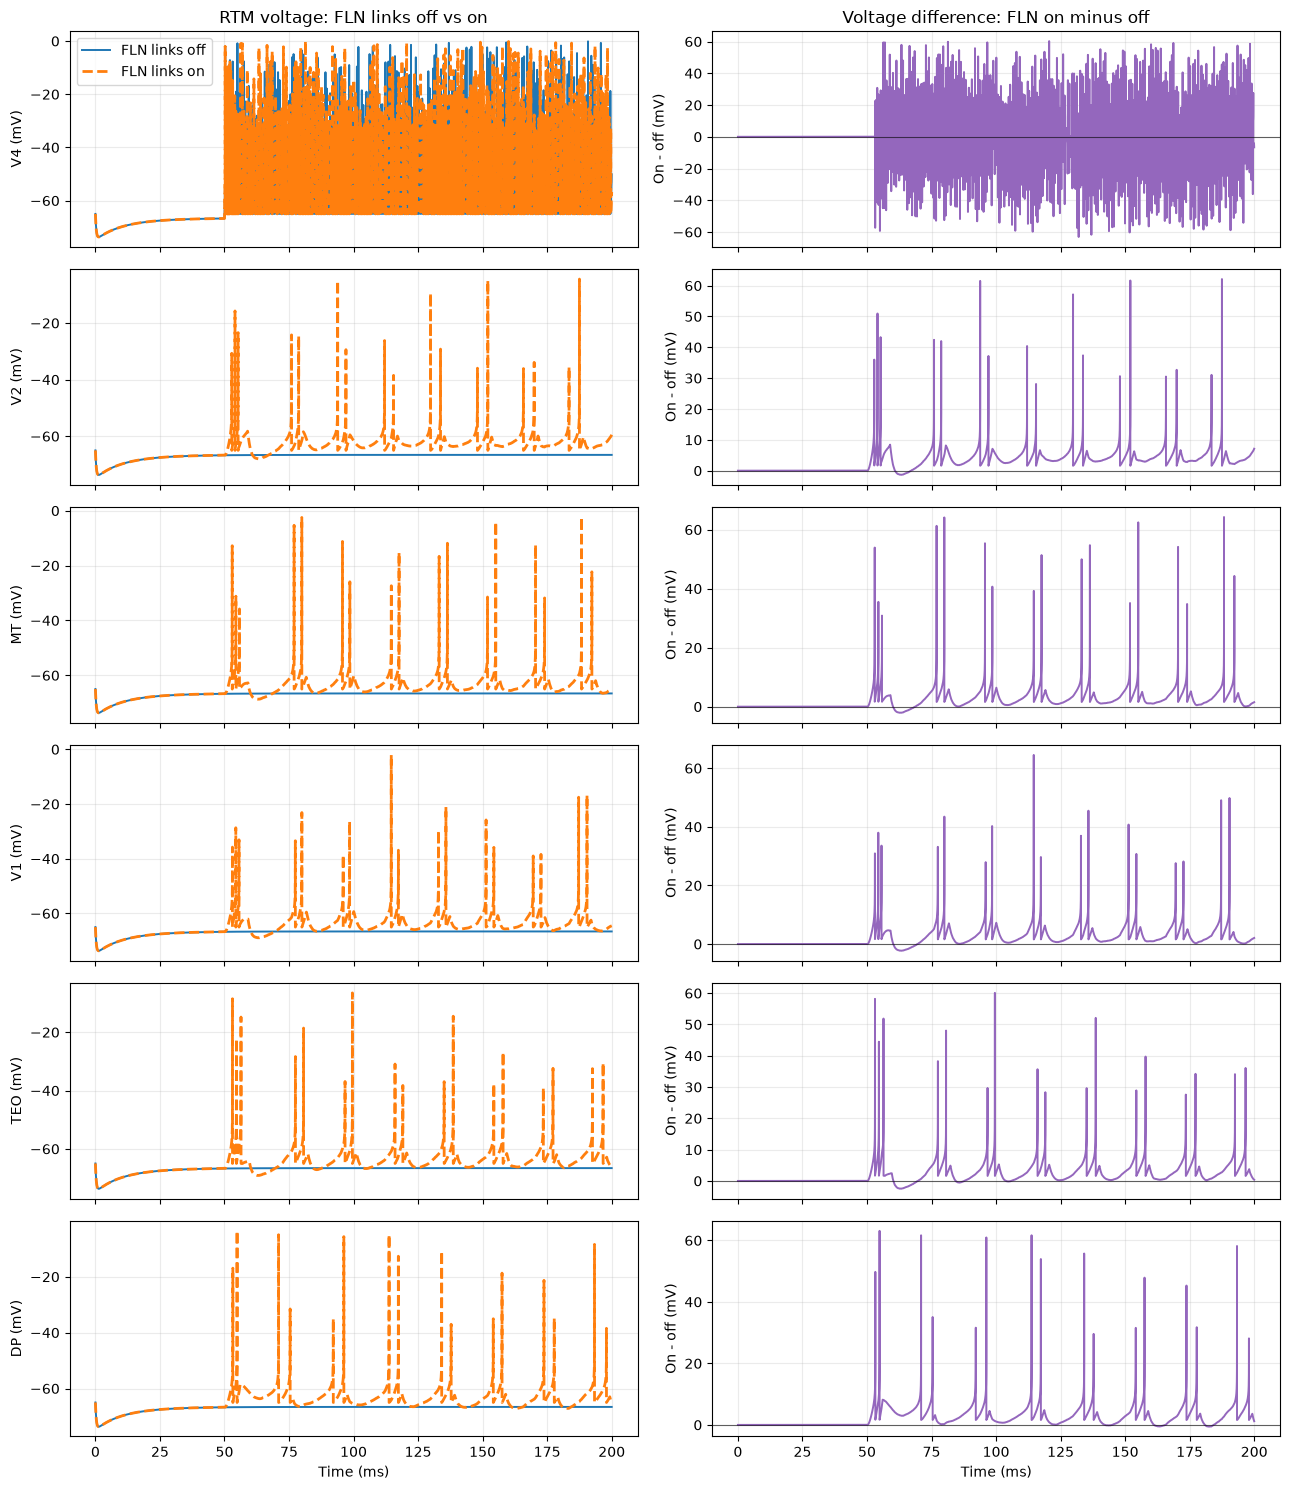

Strongest V4 outgoing targets:
V4 -> V2: FLN weight 0.2139
V4 -> MT: FLN weight 0.1908
V4 -> V1: FLN weight 0.1800
V4 -> TEO: FLN weight 0.1796
V4 -> DP: FLN weight 0.1645


In [41]:
v4_index = area_labels.index("V4")
v4_outgoing = fln_weights[:, v4_index].copy()
v4_outgoing[v4_index] = 0.0
target_order = np.argsort(v4_outgoing)[::-1]
target_indices = [i for i in target_order if v4_outgoing[i] > 0][:5]
areas_to_plot = [v4_index] + target_indices

fig, axes = plt.subplots(
    len(areas_to_plot), 2,
    figsize=(13, 2.5 * len(areas_to_plot)),
    sharex=True,
)
axes = np.atleast_2d(axes)
for row, area_idx in enumerate(areas_to_plot):
    ax_voltage = axes[row, 0]
    ax_difference = axes[row, 1]
    uncoupled_v = uncoupled["rtm_voltage_mv"][:, area_idx]
    connected_v = connected["rtm_voltage_mv"][:, area_idx]
    ax_voltage.plot(
        uncoupled["time_ms"], uncoupled_v,
        color="tab:blue", linestyle="-", linewidth=1.4,
        label="FLN links off",
    )
    ax_voltage.plot(
        connected["time_ms"], connected_v,
        color="tab:orange", linestyle="--", linewidth=2.0,
        label="FLN links on",
    )
    ax_voltage.set_ylabel(f"{area_labels[area_idx]} (mV)")
    ax_voltage.grid(alpha=0.25)

    difference_mv = connected_v - uncoupled_v
    ax_difference.plot(
        connected["time_ms"], difference_mv,
        color="tab:purple", linewidth=1.4,
    )
    ax_difference.axhline(0, color="black", linewidth=0.8, alpha=0.6)
    ax_difference.set_ylabel("On - off (mV)")
    ax_difference.grid(alpha=0.25)
    print(
        f"{area_labels[area_idx]}: maximum absolute voltage difference = "
        f"{np.max(np.abs(difference_mv)):.6g} mV"
    )

axes[0, 0].legend()
axes[0, 0].set_title("RTM voltage: FLN links off vs on")
axes[0, 1].set_title("Voltage difference: FLN on minus off")
axes[-1, 0].set_xlabel("Time (ms)")
axes[-1, 1].set_xlabel("Time (ms)")
plt.tight_layout()
plt.show()

print("Strongest V4 outgoing targets:")
for area_idx in target_indices:
    print(f"V4 -> {area_labels[area_idx]}: FLN weight {v4_outgoing[area_idx]:.4f}")


## Step 9: Inspect the local WB network in V4

This raster shows WB spikes from V4's 40-cell inhibitory network. The voltage plot records all 40 WB cells in V4, so you can see whether the local population responds to V4 RTM activity.

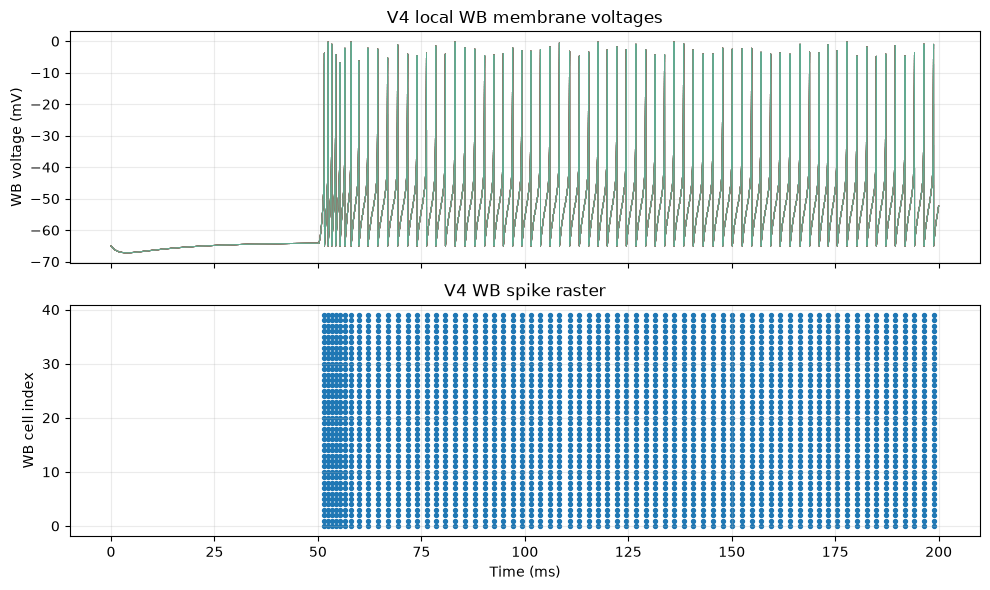

In [42]:
v4_wb_start = v4_index * n_wb_per_area
v4_wb_end = v4_wb_start + n_wb_per_area
v4_wb_mask = (
    (connected["wb_spike_cell"] >= v4_wb_start)
    & (connected["wb_spike_cell"] < v4_wb_end)
)
v4_wb_spike_cells = connected["wb_spike_cell"][v4_wb_mask] - v4_wb_start
v4_wb_spike_times = connected["wb_spike_times_ms"][v4_wb_mask]

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for cell_idx in range(n_wb_per_area):
    axes[0].plot(
        connected["time_ms"],
        connected["v4_wb_voltage_mv"][:, cell_idx],
        alpha=0.5,
        linewidth=0.7,
    )
axes[0].set_ylabel("WB voltage (mV)")
axes[0].set_title("V4 local WB membrane voltages")
axes[1].scatter(v4_wb_spike_times, v4_wb_spike_cells, s=8)
axes[1].set_ylabel("WB cell index")
axes[1].set_xlabel("Time (ms)")
axes[1].set_title("V4 WB spike raster")
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## How to interpret this prototype

- There are 40 brain areas, each with 1 RTM cell and 40 WB cells: 40 RTM cells and 1,600 WB cells total.
- W_local connects WB cells only within the same brain area. Its current default is all-to-all without self-connections, following one option in the supplied MATLAB function.
- FLN connects RTM cells across areas. FLN gives direction and relative weights; interarea_total_conductance sets the total strength scale.
- RTM-to-WB excitation and WB-to-RTM inhibition form local feedback in each area.
- WB-to-WB connections are inhibitory in this prototype. The MATLAB W function defines adjacency only, not synaptic sign or strength, so those are explicit modeling assumptions here.
- The local W alternatives in the MATLAB file are commented out; this notebook implements the all-to-all option only.
- Current units and conductances are provisional. One RTM and 40 WB cells per area do not represent a measured population size.
- This notebook has no propagation delays, noise, or parameter calibration. Compare the FLN-off control before drawing conclusions from the connected run.